# Stage 2: Entanglement swapping at a relay

**Question:** nodes A and B are too far apart for one link. A relay M sits in the middle and shares
one pair with A and one with B. Can M turn these into a single A–B pair?

**How it works.** M performs a *Bell-state measurement* (CNOT, Hadamard, measure both qubits) on its two qubits.
This gives two classical bits. M sends them to B, which applies an X and/or Z correction.
A and B are now entangled, although they never interacted. This is exactly teleportation, applied to half of an entangled pair.

In PennyLane this uses **mid-circuit measurements** (`qml.measure`) and **classically controlled gates** (`qml.cond`),
so the classical feed-forward is modelled explicitly.

Wires: 0 = A, 1 and 2 = relay M, 3 = B.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qnet import physics as P, quantum as Q, plotstyle as S
S.apply()

In [2]:
import pennylane as qml
swap = Q.make_swap_circuit("dm")
print(qml.draw(swap)(0.9, 0.9))

0: ──H─╭●──────────────────────────────────────────────────┤ ╭DensityMatrix
1: ────╰X──DepolarizingChannel(0.07)─╭●──H──┤↗├────────────┤ │             
2: ──H─╭●────────────────────────────╰X──────║───┤↗├───────┤ │             
3: ────╰X──DepolarizingChannel(0.07)─────────║────║───X──Z─┤ ╰DensityMatrix
                                             ╚════║═══║══╝                 
                                                  ╚═══╝                    


## 1. Swapping multiplies the Werner weights

Theory says that if the two links have weights $w_1$ and $w_2$, the swapped pair has $w = w_1 w_2$.
Check this by simulation over a grid of link qualities.

max |simulation - theory| = 1.9761969838327786e-14


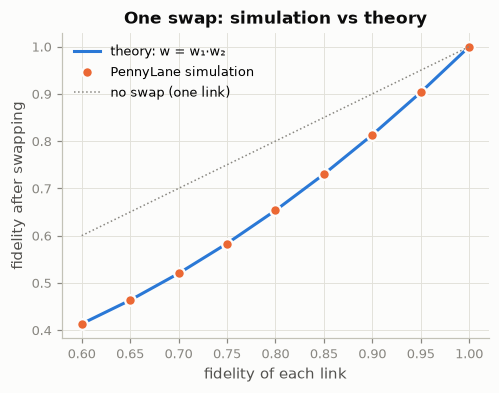

In [3]:
F_link = np.linspace(0.6, 1.0, 9)
w_link = (4 * F_link - 1) / 3
F_sim = np.array([Q.fidelity(swap(w, w)) for w in w_link])
F_th = Q.werner_fidelity(w_link ** 2)
print("max |simulation - theory| =", np.abs(F_sim - F_th).max())

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.plot(F_link, F_th, label="theory: w = w₁·w₂", color=S.SERIES[0])
ax.plot(F_link, F_sim, "o", label="PennyLane simulation", color=S.SERIES[1], ms=7, mec="#fcfcfb", mew=1.5)
ax.plot(F_link, F_link, color=S.THRESH, lw=1, ls=":", label="no swap (one link)")
ax.set(xlabel="fidelity of each link", ylabel="fidelity after swapping", title="One swap: simulation vs theory")
ax.legend()
S.save(fig, "02_swap_vs_theory")

## 2. Quality drops with every hop

A repeater chain of *n* links needs *n − 1* swaps, so the end-to-end weight is $w^n$.
The plot shows where common link fidelities stop supporting QKD (F > 0.835) and stop being entangled at all (F > 0.5).

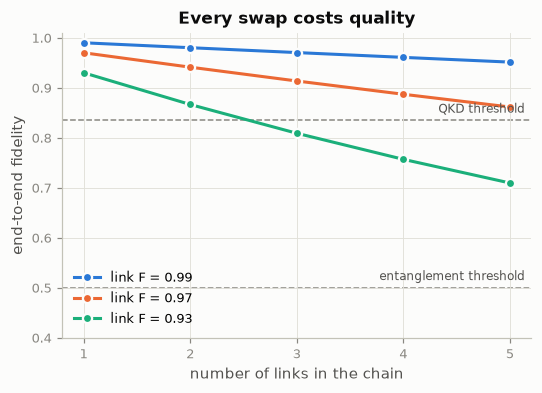

In [4]:
hops = [1, 2, 3, 4, 5]
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for i, F1 in enumerate([0.99, 0.97, 0.93]):
    w1 = (4 * F1 - 1) / 3
    F_end = [Q.fidelity(Q.make_chain_circuit(n, "dm")(w1)) if n <= 3 else Q.werner_fidelity(w1 ** n)
             for n in hops]   # n <= 3 simulated with PennyLane; larger chains use the checked formula
    ax.plot(hops, F_end, "-o", label=f"link F = {F1}", mec="#fcfcfb", mew=1.5)
S.threshold(ax, 0.835, "QKD threshold")
S.threshold(ax, 0.5, "entanglement threshold")
ax.set(xlabel="number of links in the chain", ylabel="end-to-end fidelity", xticks=hops,
       title="Every swap costs quality", ylim=(0.4, 1.01))
ax.legend(loc="lower left")
S.save(fig, "02_chain_hops")

## 3. A noisy relay

Real Bell measurements use imperfect two-qubit gates. We add depolarising noise of weight $w_\text{BSM}$
to the relay's measurement and see how it compounds with link noise.

In [5]:
for w_bsm in [1.0, 0.98, 0.95]:
    F = Q.fidelity(swap(0.95, 0.95, w_bsm=w_bsm))
    print(f"relay quality w_BSM={w_bsm:.2f}: end-to-end F = {F:.4f} "
          f"(theory {Q.werner_fidelity(0.95*0.95*w_bsm):.4f})")

relay quality w_BSM=1.00: end-to-end F = 0.9269 (theory 0.9269)
relay quality w_BSM=0.98: end-to-end F = 0.9133 (theory 0.9133)
relay quality w_BSM=0.95: end-to-end F = 0.8930 (theory 0.8930)


## 4. An honest note on rate

Swapping alone does **not** beat fibre loss. Both photons must survive half the distance at the same time,
and $\eta(L/2)^2 = \eta(L)$. A linear-optics Bell measurement also succeeds only 50% of the time.
The rate gain needs **quantum memories**: each half-link can then succeed independently and wait for the other.
That means waiting, and waiting costs quality, which is Stage 3.

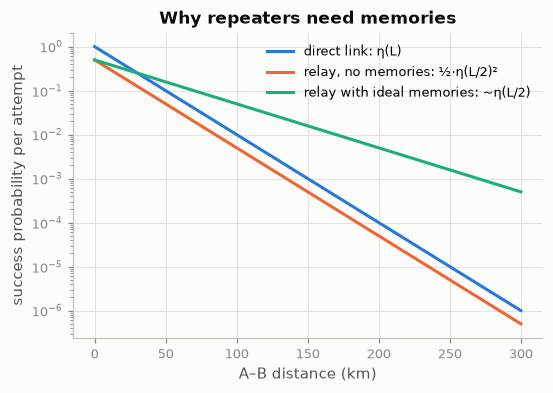

In [6]:
L = np.linspace(0, 300, 61)
eta = lambda x: P.fibre_transmission(x)
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.semilogy(L, eta(L), label="direct link: η(L)")
ax.semilogy(L, 0.5 * eta(L / 2) ** 2, label="relay, no memories: ½·η(L/2)²")
ax.semilogy(L, 0.5 * eta(L / 2), label="relay with ideal memories: ~η(L/2)")
ax.set(xlabel="A–B distance (km)", ylabel="success probability per attempt", title="Why repeaters need memories")
ax.legend()
S.save(fig, "02_rate_scaling")

## Takeaways

* Swapping is simulated with real classical feed-forward and matches theory to machine precision ($w = w_1 w_2$).
* Quality decays as $w^n$ over *n* links. With 93% links, even two hops are below the QKD threshold.
* Rate improves only with memories, and memories must wait for classical messages.